# Concrete Compressive Strength Prediction Using Machine Learning

## 1. Project Overview

Concrete compressive strength is an important property used to assess the performance of concrete in construction. It depends on the proportions of different ingredients and the curing age of the concrete.

This project uses machine-learning regression algorithms to predict concrete compressive strength from eight input features.

## 2. Project Objectives

- Understand the concrete dataset and its characteristics.
- Identify missing values and duplicate records.
- Perform exploratory data analysis (EDA).
- Study relationships between concrete ingredients and compressive strength.
- Train and compare multiple regression algorithms.
- Evaluate model performance using MAE, RMSE, and R².
- Select a candidate model using cross-validation.
- Predict compressive strength for a sample concrete mix.

## 3. Problem Statement

Develop a regression model that estimates concrete compressive strength using ingredient quantities and curing age.

## 4. Machine-Learning Approach

This project follows a supervised learning approach. The input variables are concrete mix characteristics, and the target variable is compressive strength.

## 5. Expected Outcome

Identify a model that provides accurate predictions on unseen test data while clearly documenting its limitations and evaluation results.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv(r"C:\Users\DELL\concrete.csv")

In [3]:
# Dataset overview
print("Dataset dimensions:", df.shape)
print("\nColumn names and data types:")
display(pd.DataFrame({"column": df.columns, "dtype": df.dtypes.astype(str).values}))
print("First five rows:")
display(df.head())
print("Random five rows:")
display(df.sample(5, random_state=37))
print("Dataset information:")
df.info()

Dataset dimensions: (1030, 9)

Column names and data types:


,column,dtype
0,cement,float64
1,slag,float64
2,ash,float64
3,water,float64
4,superplastic,float64
5,coarseagg,float64
6,fineagg,float64
7,age,int64
8,strength,float64


First five rows:


,cement,slag,ash,water,superplastic,coarseagg,fineagg,age,strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30


Random five rows:


,cement,slag,ash,water,superplastic,coarseagg,fineagg,age,strength
730,331.0,0.0,0.0,192.0,0.0,1025.0,821.0,120,39.38
822,322.0,0.0,0.0,203.0,0.0,974.0,800.0,28,25.18
670,305.3,203.5,0.0,203.5,0.0,965.4,631.0,28,43.38
597,272.8,181.9,0.0,185.7,0.0,1012.4,714.3,28,31.38
382,505.0,0.0,60.0,195.0,0.0,1030.0,630.0,28,64.02


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   cement        1030 non-null   float64
 1   slag          1030 non-null   float64
 2   ash           1030 non-null   float64
 3   water         1030 non-null   float64
 4   superplastic  1030 non-null   float64
 5   coarseagg     1030 non-null   float64
 6   fineagg       1030 non-null   float64
 7   age           1030 non-null   int64  
 8   strength      1030 non-null   float64
dtypes: float64(8), int64(1)
memory usage: 72.6 KB


## Dataset Overview

The dataset contains measurements of concrete ingredients, concrete age, and compressive strength.

The eight input features are cement, slag, ash, water, superplasticizer, coarse aggregate, fine aggregate, and age.

The target variable is "strength", which the model attempts to predict.

The original dataset contains 1,030 rows and nine columns. Dataset dimensions and data types are checked before preprocessing.

In [4]:
# Data quality checks
print("Missing value by columns: ")
print(df.isna().sum().to_frame("Missing_count"))

print("\nDuplicate Rows: ", df.duplicated().sum())

print("\nDiscriptive Statestics:")
df.describe().T

Missing value by columns: 
              Missing_count
cement                    0
slag                      0
ash                       0
water                     0
superplastic              0
coarseagg                 0
fineagg                   0
age                       0
strength                  0

Duplicate Rows:  25

Discriptive Statestics:


,count,mean,std,min,25%,50%,75%,max
cement,1030.0,281.167864,104.506364,102.00,192.375,272.900,350.000,540.0
slag,1030.0,73.895825,86.279342,0.00,0.000,22.000,142.950,359.4
ash,1030.0,54.188350,63.997004,0.00,0.000,0.000,118.300,200.1
water,1030.0,181.567282,21.354219,121.80,164.900,185.000,192.000,247.0
superplastic,1030.0,6.204660,5.973841,0.00,0.000,6.400,10.200,32.2
coarseagg,1030.0,972.918932,77.753954,801.00,932.000,968.000,1029.400,1145.0
fineagg,1030.0,773.580485,80.175980,594.00,730.950,779.500,824.000,992.6
age,1030.0,45.662136,63.169912,1.00,7.000,28.000,56.000,365.0
strength,1030.0,35.817961,16.705742,2.33,23.710,34.445,46.135,82.6


## Data Cleaning

The initial dataset contains 1,030 records and 25 duplicate rows. No missing values were detected in the original data.

Duplicate records are removed to reduce redundant observations. The cleaned dataset contains 1,005 rows.

Duplicate removal does not guarantee that all data-quality problems have been eliminated, so the dataset should also be checked for invalid values and unusual observations.

In [5]:
# Remove duplicate records
df = df.drop_duplicates()

In [6]:
print("\nDiscriptive Statestics:")
df.describe().T


Discriptive Statestics:


,count,mean,std,min,25%,50%,75%,max
cement,1005.0,278.631343,104.344261,102.00,190.70,265.0,349.00,540.0
slag,1005.0,72.043483,86.170807,0.00,0.00,20.0,142.50,359.4
ash,1005.0,55.536318,64.207969,0.00,0.00,0.0,118.30,200.1
water,1005.0,182.075323,21.339334,121.80,166.60,185.7,192.90,247.0
superplastic,1005.0,6.033234,5.919967,0.00,0.00,6.1,10.00,32.2
coarseagg,1005.0,974.376816,77.579667,801.00,932.00,968.0,1031.00,1145.0
fineagg,1005.0,772.688259,80.340435,594.00,724.30,780.0,822.20,992.6
age,1005.0,45.856716,63.734692,1.00,7.00,28.0,56.00,365.0
strength,1005.0,35.250378,16.284815,2.33,23.52,33.8,44.87,82.6


# Exploratory Data Analysis (EDA)

Exploratory data analysis is used to understand the dataset before building machine-learning models.

The analysis examines:
- Distributions of input features and the target variable.
- Variation in concrete compressive strength.
- Correlations between numeric variables.
- Relationships between individual features and strength.

EDA helps identify patterns and potential data-quality concerns. However, observed relationships do not necessarily imply causation.

## Target Variable Analysis

The target variable is `strength`, representing concrete compressive strength.

Descriptive statistics summarize its central tendency, variability, and range. The histogram helps visualize the distribution and identify possible skewness or extreme observations.

The observed distribution should be interpreted from the generated plots rather than assuming that the target variable follows a normal distribution.

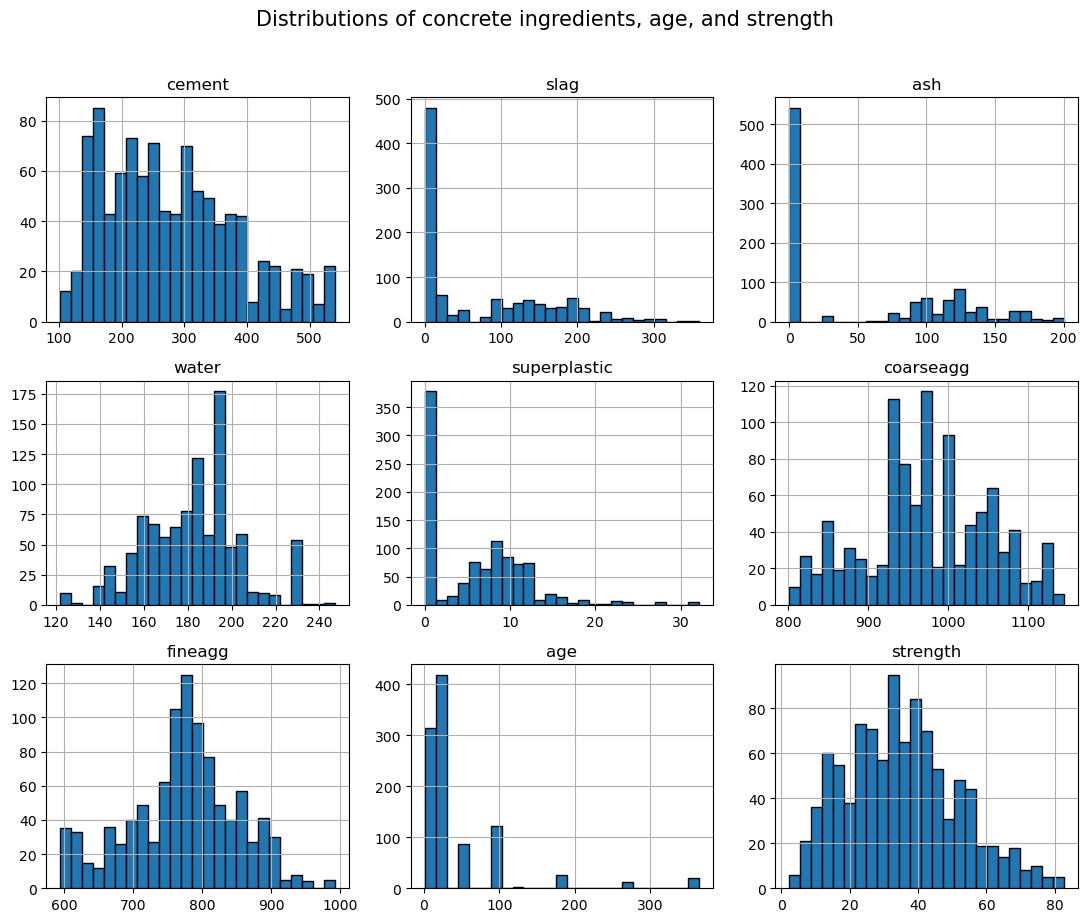

In [7]:
df.hist(figsize=(11,9), bins=25, edgecolor="black")
plt.suptitle("Distributions of concrete ingredients, age, and strength", y=1.02, fontsize=15)
plt.tight_layout()
plt.show()

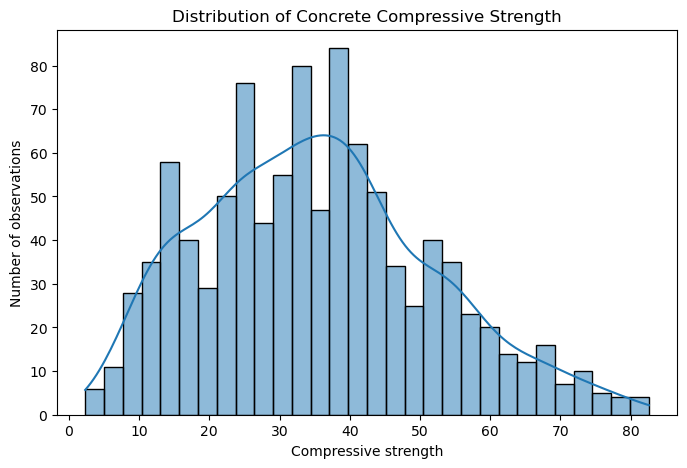

In [8]:
plt.figure(figsize=(8,5))
sns.histplot(df["strength"], kde=True, bins=30)
plt.title("Distribution of Concrete Compressive Strength")
plt.xlabel("Compressive strength")
plt.ylabel("Number of observations")
plt.show()

In [9]:
# Summary statistics of the target variable
strength_summary = (df["strength"].describe())
display(strength_summary.to_frame("Compressive Strength"))

,Compressive Strength
count,1005.000000
mean,35.250378
std,16.284815
min,2.330000
25%,23.520000
50%,33.800000
75%,44.870000
max,82.600000


# Correlation Analysis

Correlation analysis measures the direction and strength of linear relationships between numeric variables.

A positive correlation indicates that two variables tend to increase together, while a negative correlation indicates that one tends to decrease as the other increases.

Correlation alone does not capture every nonlinear relationship and should not be treated as proof of causation.

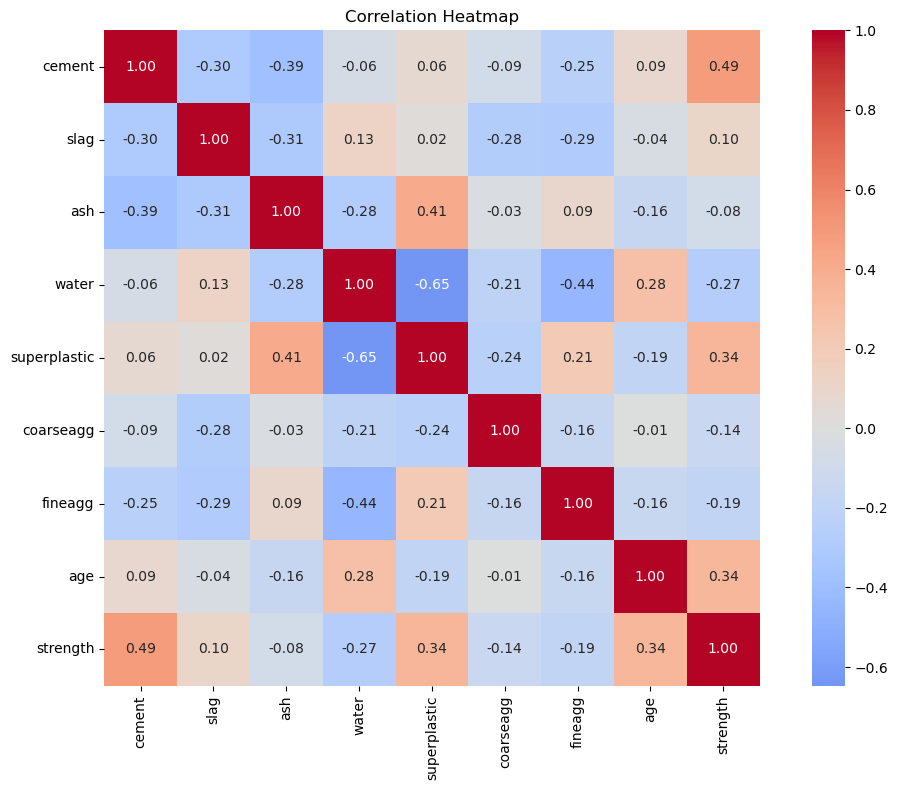

In [10]:
corr = df.corr(numeric_only=True)
plt.figure(figsize=(11 ,8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

In [11]:
print("Features with strongest absolute linear correlation with strength:")
display(corr["strength"].drop("strength").sort_values(key=lambda s: s.abs(), ascending=False).to_frame("correlation_with_strength"))

Features with strongest absolute linear correlation with strength:


,correlation_with_strength
cement,0.488283
superplastic,0.344209
age,0.337367
water,-0.269624
fineagg,-0.186448
coarseagg,-0.144717
slag,0.103374
ash,-0.080648


### Correlation Findings

Cement shows the strongest positive linear correlation with strength among the input variables in this dataset. Superplasticizer and age also show positive correlations, while water shows a negative correlation.

These findings describe pairwise linear associations. The machine-learning models may capture additional nonlinear relationships and interactions between features.

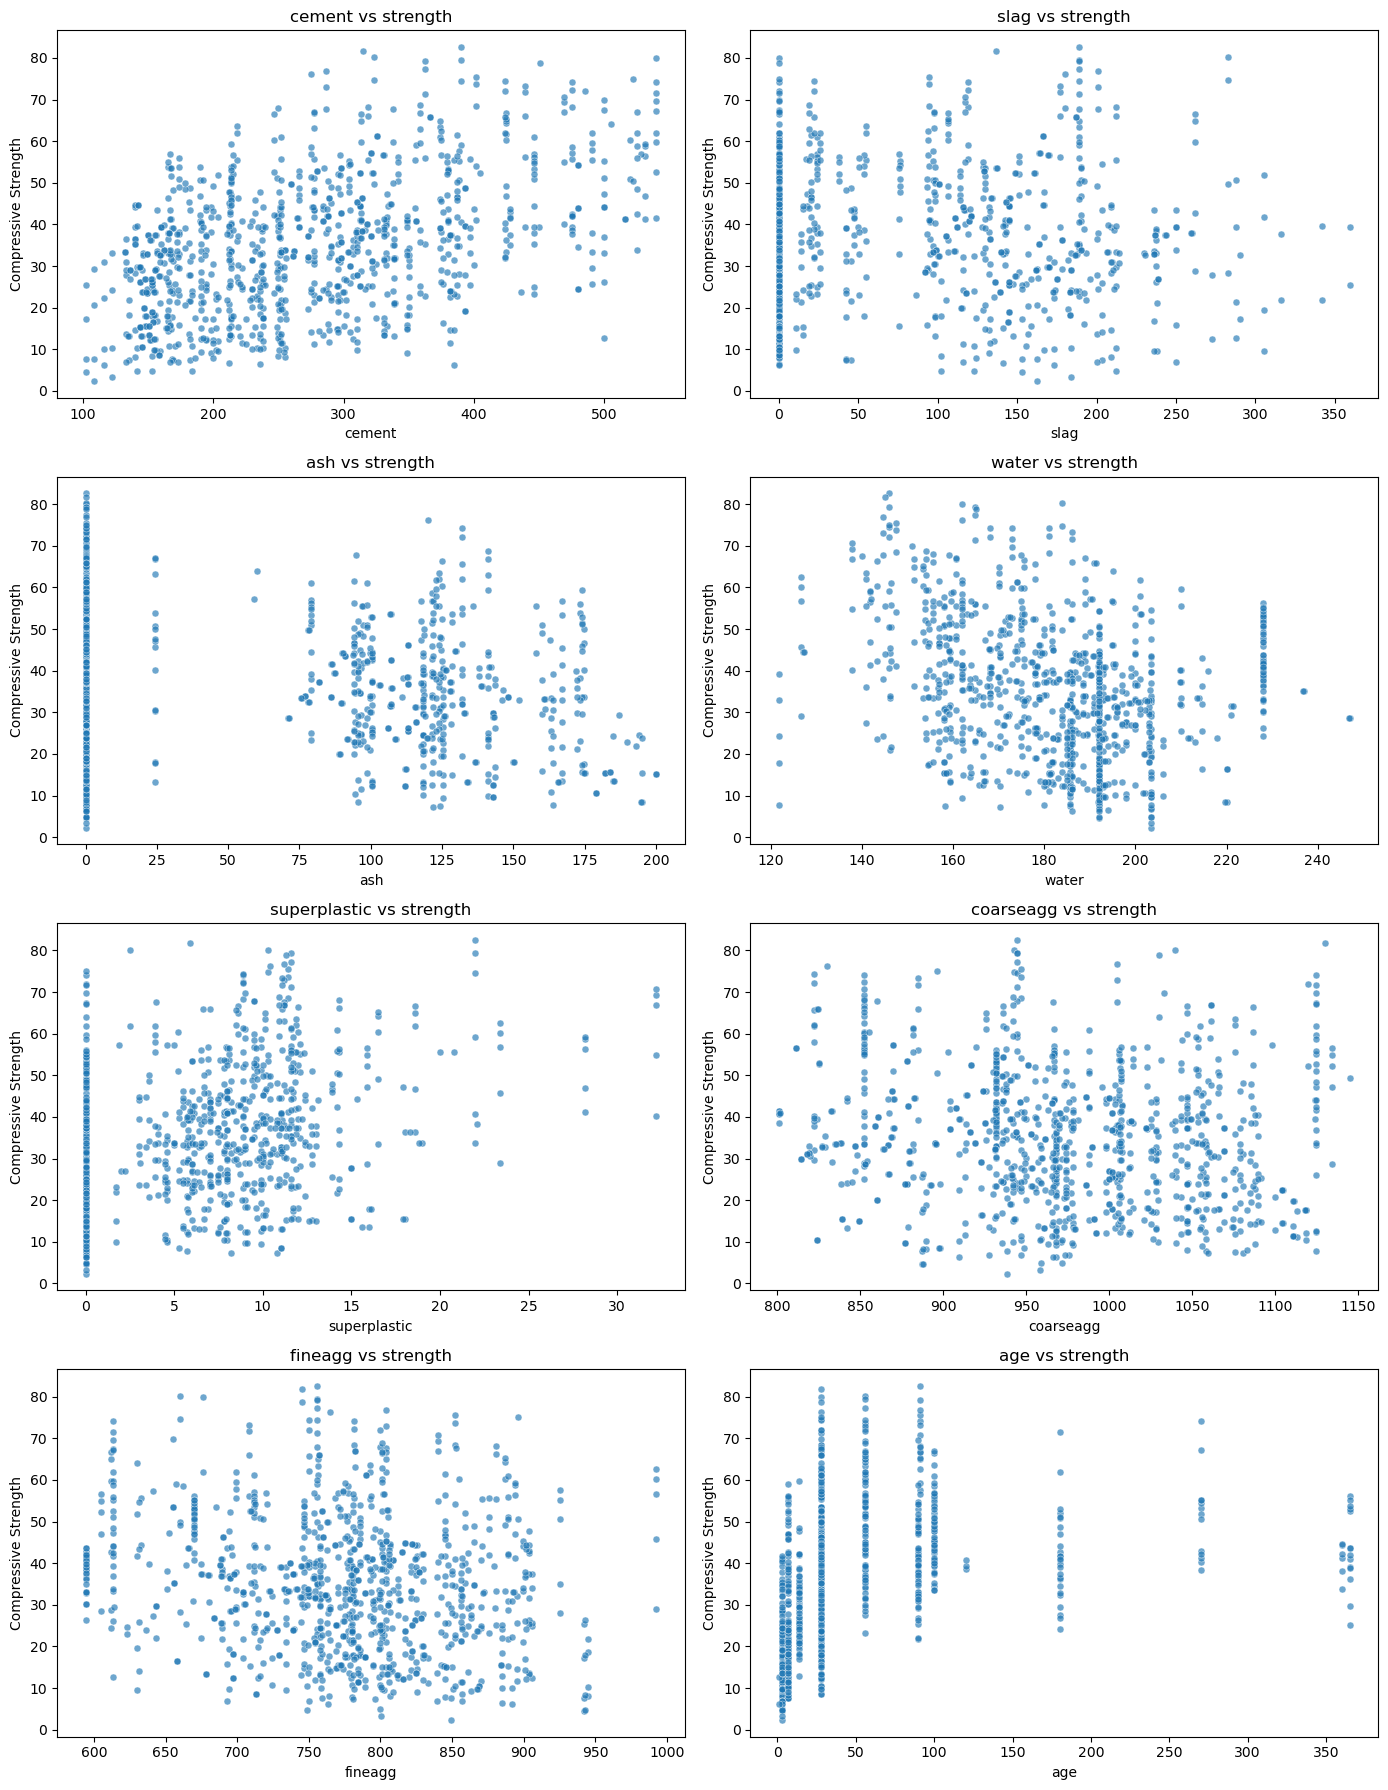

In [12]:
# Relationship between each feature and strength
Features = [c for c in df.columns if c != "strength"]
fig, axes = plt.subplots(4, 2, figsize=(14,18))
axes = axes.flatten()

for ax, col in zip(axes,Features):
    sns.scatterplot(data=df, x=col, y="strength", alpha=0.65, s=25, ax=ax)
    ax.set_title(f"{col} vs strength")
    ax.set_xlabel(col)
    ax.set_ylabel("Compressive Strength")

for ax in axes [len(Features):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

# Machine Learning: Model Development and Evaluation

This section develops regression models to predict concrete compressive strength.

Regression is appropriate because the target variable is continuous.

Multiple algorithms are compared to determine which provides the best predictive performance. Model evaluation uses a separate test set and five-fold cross-validation on the training data.

In [13]:
from sklearn.model_selection import train_test_split, cross_validate, KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, GradientBoostingRegressor, HistGradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [14]:
# We use an 80% training set and 20% test set
x = df.drop(columns="strength")
y = df["strength"]

x_train,x_test,y_train,y_test = train_test_split(x,y, test_size=0.20, random_state=47)

print("Training rows:", len(x_train))
print("Testing rows:", len(x_test))
print("Number of features:", x_train.shape[1])
print("Feature names:", x.columns.tolist())

Training rows: 804
Testing rows: 201
Number of features: 8
Feature names: ['cement', 'slag', 'ash', 'water', 'superplastic', 'coarseagg', 'fineagg', 'age']


## Regression Algorithms

The following algorithms are evaluated:

1. Dummy Regressor: establishes a baseline using the mean target value.
2. Linear Regression: models a linear relationship between features and the target.
3. Ridge Regression: adds L2 regularization to linear regression.
4. Random Forest: combines predictions from multiple decision trees.
5. Extra Trees: uses randomized decision trees to model nonlinear relationships.
6. Gradient Boosting: builds an ensemble of sequentially improved trees.
7. HistGradientBoosting: uses histogram-based gradient boosting for regression.
8. Support Vector Regression (SVR): models nonlinear relationships using an RBF kernel.

Pipelines combine preprocessing and model fitting to ensure that preprocessing is learned from the appropriate training data.

## Initial Test-Set Evaluation

Each model is trained on the training set and evaluated on the held-out test set.

- MAE measures the average absolute prediction error.
- RMSE penalizes larger errors more heavily than MAE.
- R² measures how well the model explains variation in the target relative to a mean-based reference.

Lower MAE and RMSE values are better. Higher R² is generally better.

The test set should not be used repeatedly to tune model parameters, as this can lead to overly optimistic estimates of performance.

In [15]:
# Train multiple machine-learning models
models = {
    "Dummy baseline": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", DummyRegressor(strategy="mean"))
    ]),
    "Linear Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LinearRegression())
    ]),
    "Ridge Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", Ridge(alpha=1.0))
    ]),
    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestRegressor(n_estimators=300, random_state=37, min_samples_leaf=1, n_jobs=-1))
    ]),
    "Extra Trees": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", ExtraTreesRegressor(n_estimators=300, random_state=37, min_samples_leaf=1, n_jobs=-1))
    ]),
    "Gradient Boosting": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", GradientBoostingRegressor(random_state=37))
    ]),
    "HistGradientBoosting": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", HistGradientBoostingRegressor(random_state=37))
    ]),
    "SVR (RBF)": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", SVR(kernel="rbf", C=30, epsilon=0.1))
    ])
}

In [16]:
results = []
fitted_models = {}

for name, model in models.items():
    model.fit(x_train, y_train)
    pred = model.predict(x_test)
    fitted_models[name] = model
    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R2": r2_score(y_test, pred)
    })

results_df = pd.DataFrame(results).sort_values("RMSE").reset_index(drop=True)
display(results_df.round(4))

,Model,MAE,RMSE,R2
0,HistGradientBoosting,2.8125,4.0153,0.9385
1,Extra Trees,2.7628,4.5656,0.9205
2,Random Forest,3.2653,4.6647,0.9170
3,Gradient Boosting,3.7110,4.9092,0.9081
4,SVR (RBF),4.3726,6.0753,0.8592
5,Ridge Regression,7.8297,9.6042,0.6482
6,Linear Regression,7.8238,9.6053,0.6481
7,Dummy baseline,13.2597,16.3943,-0.0252


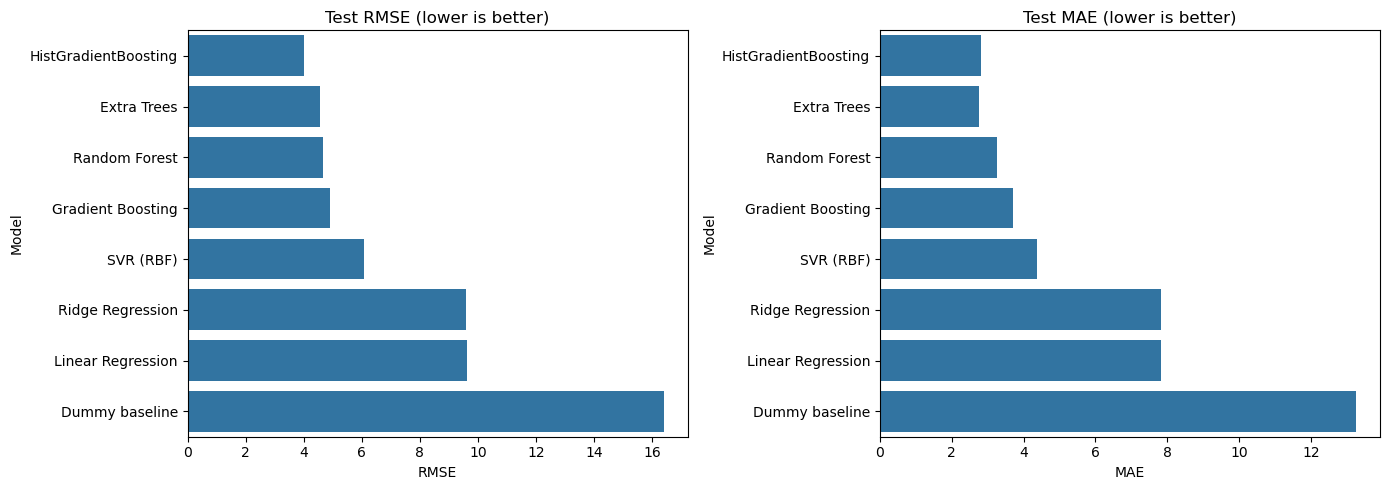

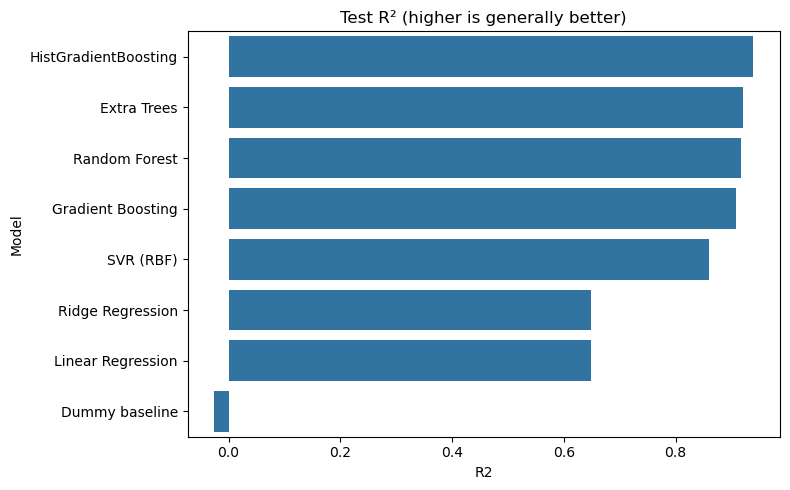

In [17]:
# Visualize model comparison
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(data=results_df, x="RMSE", y="Model", ax=axes[0])
axes[0].set_title("Test RMSE (lower is better)")
sns.barplot(data=results_df, x="MAE", y="Model", ax=axes[1])
axes[1].set_title("Test MAE (lower is better)")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
sns.barplot(data=results_df, x="R2", y="Model")
plt.title("Test R² (higher is generally better)")
plt.tight_layout()
plt.show()

## Cross-Validation Results

Five-fold cross-validation compares model performance across different splits of the training data.

The model with the lowest mean cross-validation RMSE is selected as the candidate model. The mean and standard deviation of cross-validation MAE help describe its prediction error and variability across folds.

The held-out test set is then used to evaluate the selected candidate model.

In [18]:
# Cross-validation for a more reliable comparison
cv = KFold(n_splits=5, shuffle=True, random_state=37)
cv_rows = []

for name, model in models.items():
    scores = cross_validate(
        model, x_train, y_train, cv=cv,
        scoring={"mae": "neg_mean_absolute_error", "rmse": "neg_root_mean_squared_error", "r2": "r2"},
        n_jobs=-1,
        return_train_score=False
    )
    cv_rows.append({
        "Model": name,
        "CV MAE mean": -scores["test_mae"].mean(),
        "CV MAE std": scores["test_mae"].std(),
        "CV RMSE mean": -scores["test_rmse"].mean(),
        "CV R2 mean": scores["test_r2"].mean()
    })

cv_results_df = pd.DataFrame(cv_rows).sort_values("CV RMSE mean").reset_index(drop=True)
display(cv_results_df.round(4))

,Model,CV MAE mean,CV MAE std,CV RMSE mean,CV R2 mean
0,HistGradientBoosting,3.4451,0.3126,5.0798,0.9018
1,Extra Trees,3.5235,0.3481,5.2900,0.8931
2,Gradient Boosting,3.9830,0.2885,5.3980,0.8891
3,Random Forest,3.8986,0.1809,5.4392,0.8869
4,SVR (RBF),4.7143,0.3612,6.5804,0.8345
5,Ridge Regression,8.3307,0.4299,10.5508,0.5751
6,Linear Regression,8.3242,0.4348,10.5521,0.5750
7,Dummy baseline,13.1758,0.7455,16.2500,-0.0062


## Candidate Model Selection and Evaluation

The candidate model is selected using the lowest mean RMSE from five-fold cross-validation on the training data.

The selected model is then evaluated on the held-out test set to assess its predictive performance on data not used during model fitting.

In [19]:
# Select the candidate model and inspect predictions
best_name = cv_results_df.iloc[0]["Model"]
best_model = fitted_models[best_name]
best_predictions = best_model.predict(x_test)

print("Candidate selected by lowest mean CV RMSE:", best_name)
print("Final held-out test metrics:")
print(f"MAE : {mean_absolute_error(y_test, best_predictions):.3f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, best_predictions)):.3f}")
print(f"R²  : {r2_score(y_test, best_predictions):.3f}")

comparison = pd.DataFrame({
    "Actual strength": y_test.to_numpy(),
    "Predicted strength": best_predictions,
})
comparison["Absolute error"] = abs(comparison["Actual strength"] - comparison["Predicted strength"])
display(comparison.head(10).round(3))

Candidate selected by lowest mean CV RMSE: HistGradientBoosting
Final held-out test metrics:
MAE : 2.813
RMSE: 4.015
R²  : 0.939


,Actual strength,Predicted strength,Absolute error
0,19.77,21.046,1.276
1,29.73,28.320,1.410
2,25.97,24.483,1.487
3,53.30,50.994,2.306
4,21.60,24.260,2.660
5,35.87,37.164,1.294
6,33.00,29.802,3.198
7,28.68,29.665,0.985
8,55.16,49.414,5.746
9,56.40,61.139,4.739


## Prediction Diagnostics

The actual-versus-predicted plot compares model predictions with observed concrete strengths. Points closer to the diagonal indicate more accurate predictions.

The residual plot helps identify systematic prediction errors or changes in the spread of errors.

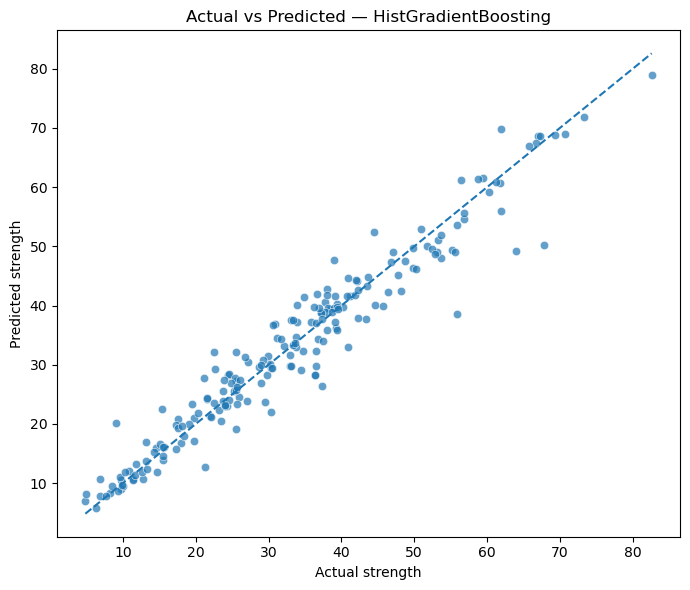

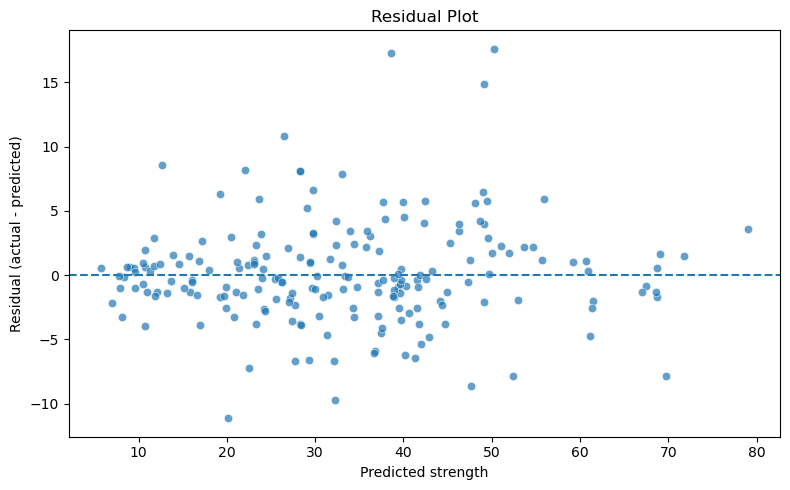

In [20]:
plt.figure(figsize=(7, 6))
sns.scatterplot(x=y_test, y=best_predictions, alpha=0.7)
low = min(y_test.min(), best_predictions.min())
high = max(y_test.max(), best_predictions.max())
plt.plot([low, high], [low, high], linestyle="--")
plt.xlabel("Actual strength")
plt.ylabel("Predicted strength")
plt.title(f"Actual vs Predicted — {best_name}")
plt.tight_layout()
plt.show()

residuals = y_test.to_numpy() - best_predictions
plt.figure(figsize=(8, 5))
sns.scatterplot(x=best_predictions, y=residuals, alpha=0.7)
plt.axhline(0, linestyle="--")
plt.xlabel("Predicted strength")
plt.ylabel("Residual (actual - predicted)")
plt.title("Residual Plot")
plt.tight_layout()
plt.show()

,Random Forest feature importance
age,0.340909
cement,0.313189
water,0.123131
slag,0.076829
superplastic,0.058149
fineagg,0.037833
coarseagg,0.030032
ash,0.019929


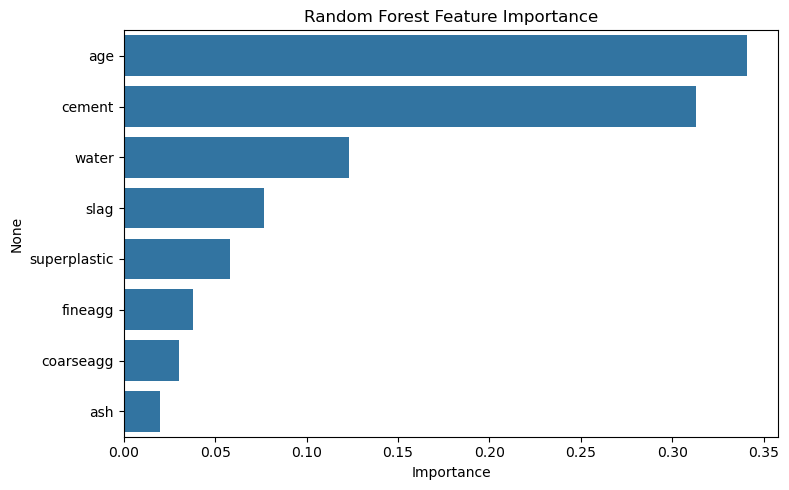

In [21]:
# Feature importance
rf_model = fitted_models["Random Forest"]
rf_estimator = rf_model.named_steps["model"]
importance = pd.Series(rf_estimator.feature_importances_, index=x.columns).sort_values(ascending=False)

display(importance.to_frame("Random Forest feature importance"))
plt.figure(figsize=(8, 5))
sns.barplot(x=importance.values, y=importance.index)
plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

## Prediction for a New Concrete Mix

The trained candidate model is used to estimate compressive strength for an example mix.

The ingredient quantities are taken from the median values in the cleaned dataset, and the concrete age is set to 28 days.

This is an illustrative prediction rather than a verified concrete mix design. The estimated value should not be used as the sole basis for construction or structural safety decisions.

In [22]:
# Predict strength for a new mix
new_mix = pd.DataFrame([{
    "cement":  (df["cement"].median()),
    "slag": (df["slag"].median()),
    "ash": (df["ash"].median()),
    "water": (df["water"].median()),
    "superplastic": (df["superplastic"].median()),
    "coarseagg": (df["coarseagg"].median()),
    "fineagg": (df["fineagg"].median()),
    "age": 28
}])

predicted_strength = best_model.predict(new_mix)[0]
display(new_mix)
print(f"Estimated compressive strength at {new_mix.loc[0, 'age']} days: {predicted_strength:.2f}")
print("This is an educational estimate; verify strength with appropriate laboratory testing.")

,cement,slag,ash,water,superplastic,coarseagg,fineagg,age
0,265.0,20.0,0.0,185.7,6.1,968.0,780.0,28


Estimated compressive strength at 28 days: 36.62
This is an educational estimate; verify strength with appropriate laboratory testing.


# Final Conclusion

This project demonstrates the application of supervised machine learning to concrete compressive strength prediction.

The workflow includes data inspection, duplicate removal, exploratory data analysis, correlation analysis, model training, test-set evaluation, cross-validation, prediction diagnostics, and feature-importance analysis.

Eight regression algorithms were compared. HistGradientBoosting achieved the lowest mean cross-validation RMSE and was selected as the candidate model.

On the held-out test set, the selected model achieved:

- MAE: approximately 2.813
- RMSE: approximately 4.015
- R²: approximately 0.939

The results indicate that the selected model can capture substantial variation in compressive strength in this dataset.

The Random Forest feature-importance analysis identified age and cement as the two most influential features under that model's importance measure.

## Limitations

- The dataset is limited to the concrete mixes represented in the available observations.
- Performance on new datasets or different concrete mix designs may differ.
- Cross-validation and test-set performance do not guarantee performance in real-world applications.
- Feature importance and correlation do not prove causation.
- Laboratory testing and engineering validation are required before using predictions for practical construction decisions.

## Future Improvements

- Tune hyperparameters using cross-validation.
- Evaluate model stability across different data splits.
- Compare permutation importance across models.
- Validate the selected model on independent concrete datasets.
- Save the final model and create a reusable prediction interface.

## Final Outcome

HistGradientBoosting is the selected candidate based on cross-validation and held-out test performance. Further independent validation is recommended before practical deployment.